<a href="https://colab.research.google.com/github/Linzdhx/Capstone/blob/model_training/Proyecto_CVW_modelo_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detección de espacios vacíos en góndolas — YOLOv8s (v2) el david es un pesado


**Proyecto de título · Cámaras de seguridad en supermercados**

El modelo detecta dos clases en imágenes de góndolas: `product` (producto en repisa) y `missing` (espacio vacío).
Debe funcionar con **cámaras de seguridad**: baja resolución, compresión, ruido y ángulos en diagonal. Por eso el entrenamiento usa aumentación que simula esas condiciones y la evaluación se hace con imágenes limpias **y** con imágenes degradadas ("cámara").

## Antes de ejecutar
1. **Pon tu API key de Roboflow**
2. En Colab abre el panel de la izquierda → 🔑 **Secrets** → agrega `ROBOFLOW_API_KEY` y activa "Notebook access".
3. Runtime → Change runtime type → **GPU (T4)**.

## Flujo
| # | Sección | Qué hace |
|---|---|---|
| 1 | Configuración | Todos los parámetros en un solo lugar |
| 2 | Dataset | Descarga desde Roboflow |
| 3 | Análisis de cajas y grid | Tamaño real de las cajas frente al grid de YOLO |
| 4 | Split 70/15/15 | Train/valid/test agrupando imágenes casi idénticas |
| 5 | Aumentación | Solo train; además crea `valid_cam` y `test_cam` |
| 6 | Entrenamiento | YOLOv8s, 640 px, 100 épocas |
| 7 | Evaluación | Limpio vs. cámara, umbral de confianza |
| 8 | ¿Vale la pena SAM? | Experimento para decidir con datos |
| 9 | Exportar | Modelo y archivos para el informe |

## Cambios respecto a v1
| Tema | v1 | v2 |
|---|---|---|
| Modelo | YOLOv8n | **YOLOv8s** |
| Split | solo `valid` (15 %, aleatorio), sin test | **train/valid/test 70/15/15**, agrupando casi-duplicados y balanceando `missing` |
| Geometría | `VerticalFlip`, perspectiva leve | **sin `VerticalFlip`**, perspectiva fuerte, distorsión de lente, `min_visibility` |
| Degradación | resolución, compresión, ruido | lo mismo, más modo monocromo (cámaras IR) |
| Desbalance | 3 copias por imagen | **6 copias** si la imagen tiene `missing`, 3 si no |
| Evaluación | solo `valid` limpio | `valid`, `test` limpios y versiones `_cam` |
| API key | texto plano | Colab Secrets |
| SAM | eliminado | **sección de decisión** con métricas |

In [ ]:
!pip install -q -U ultralytics roboflow albumentations opencv-python-headless imagehash

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 378.3/378.3 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 55.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 6.3 MB/s eta 0:00:00


## 1. Configuración
Todos los parámetros que puedes querer cambiar están en la celda siguiente. El resto del notebook los lee desde ahí.

- `SEED` fija la aleatoriedad (split, aumentación, entrenamiento) para que los resultados sean reproducibles.
- `N_AUG_MISSING > N_AUG_DEFAULT` sobremuestrea las imágenes con espacios vacíos: la clase `missing` tiene ~37 veces menos cajas que `product`.
- `FREEZE_LAYERS = 10` congela el backbone (primeras 10 capas) para reducir el sobreajuste con pocas imágenes. Si el mAP se estanca pronto, prueba `0`.

In [ ]:
import os, random, shutil, json
from pathlib import Path
import numpy as np
import pandas as pd
import yaml

# --- Reproducibilidad ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- Roboflow (la API key NO va aquí: se lee de Colab Secrets) ---
RF_WORKSPACE = "final-project-object-detection-for-instore-inventory-management"
RF_PROJECT = "empty-spaces-in-a-supermarket-hanger-1upsp"
RF_VERSION = 4
FORCE_DOWNLOAD = False          # True = vuelve a descargar aunque ya exista

# --- Rutas ---
BASE = Path("/content")
RAW_DIR = BASE / "raw_dataset"          # dataset original descargado
SPLIT_DIR = BASE / "split_dataset"      # train/valid/test sin aumentar
FINAL_DIR = BASE / "final_dataset"      # train aumentado + valid/test + sets "cámara"
RUNS_DIR = BASE / "runs" / "gondolas"   # resultados del entrenamiento

# --- Split ---
SPLIT_RATIOS = (0.70, 0.15, 0.15)       # train, valid, test
HASH_THR = 8                            # distancia phash máx. para considerar "casi-duplicadas"
MAX_GROUP_FRAC = 0.20                   # un grupo no puede superar este % del dataset
N_SPLIT_TRIES = 300                     # particiones aleatorias a probar (se elige la mejor)
MIN_MISSING_PER_SPLIT = 15              # mínimo de cajas 'missing' en valid y en test

# --- Aumentación (solo train) ---
N_AUG_DEFAULT = 3                       # copias aumentadas por imagen
N_AUG_MISSING = 6                       # copias si la imagen contiene 'missing'

# --- Modelo / entrenamiento ---
MODEL_WEIGHTS = "yolov8s.pt"
IMGSZ = 640
EPOCHS = 100
BATCH = 16
PATIENCE = 100                           # early stopping (v1 usaba 20 y paró en la época 71)
FREEZE_LAYERS = 10

print("Configuración cargada. Dataset base:", BASE)

Configuración cargada. Dataset base: /content


## 2. Dataset
Se descarga la versión de Roboflow en formato YOLOv8 (solo cajas). La API key se lee de **Colab Secrets**; si no existe, la pide por teclado sin mostrarla.

In [ ]:
def get_roboflow_key():
    """Lee la API key de Colab Secrets; si no está, la pide con getpass (no queda en el notebook)."""
    try:
        from google.colab import userdata
        return userdata.get("ROBOFLOW_API_KEY")
    except Exception:
        import getpass
        return getpass.getpass("Roboflow API key: ")


def download_dataset():
    from roboflow import Roboflow
    rf = Roboflow(api_key=get_roboflow_key())
    ds = (rf.workspace(RF_WORKSPACE).project(RF_PROJECT)
            .version(RF_VERSION).download("yolov8", location=str(RAW_DIR)))
    return ds.location


if FORCE_DOWNLOAD or not (RAW_DIR / "data.yaml").exists():
    if RAW_DIR.exists():
        shutil.rmtree(RAW_DIR)
    download_dataset()
else:
    print("Dataset ya descargado en", RAW_DIR)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/raw_dataset in yolov8:: 100%|██████████| 701/701 [00:02<00:00, 241.93it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
def load_class_names(raw_dir):
    """Lee los nombres de clase del data.yaml original (lista o diccionario)."""
    with open(Path(raw_dir) / "data.yaml") as f:
        names = yaml.safe_load(f)["names"]
    if isinstance(names, dict):
        names = [names[k] for k in sorted(names)]
    return list(names)


CLASS_NAMES = load_class_names(RAW_DIR)
# Se busca por nombre (no se asume el índice) para no confundir las clases
MISSING_ID = next((i for i, n in enumerate(CLASS_NAMES) if "missing" in n.lower()), 0)
PRODUCT_ID = next((i for i, n in enumerate(CLASS_NAMES) if "product" in n.lower()), 1)
print("Clases:", CLASS_NAMES, "| missing =", MISSING_ID, "| product =", PRODUCT_ID)

Clases: ['missing', 'product'] | missing = 0 | product = 1


In [ ]:
# ---- Utilidades de lectura/escritura de etiquetas YOLO (formato: clase x_c y_c w h, normalizado) ----
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def list_pairs(root, splits=("train", "valid", "val", "test")):
    """Devuelve [(imagen, etiqueta)] de las carpetas <root>/<split>/{images,labels} que existan."""
    pairs = []
    for sp in splits:
        img_dir = Path(root) / sp / "images"
        if not img_dir.exists():
            continue
        for ip in sorted(img_dir.iterdir()):
            lp = Path(root) / sp / "labels" / f"{ip.stem}.txt"
            if ip.suffix.lower() in IMG_EXTS and lp.exists():
                pairs.append((ip, lp))
    return pairs


def read_yolo_bboxes(label_path):
    """Lee cajas YOLO y las recorta a [0,1]; descarta cajas con ancho o alto <= 0."""
    boxes, classes = [], []
    with open(label_path) as f:
        for line in f:
            p = line.split()
            if len(p) < 5:
                continue
            c = int(float(p[0]))
            x, y, w, h = map(float, p[1:5])
            x1, y1 = max(0.0, x - w / 2), max(0.0, y - h / 2)
            x2, y2 = min(1.0, x + w / 2), min(1.0, y + h / 2)
            w, h = x2 - x1, y2 - y1
            if w <= 0 or h <= 0:
                continue
            boxes.append([(x1 + x2) / 2, (y1 + y2) / 2, w, h])
            classes.append(c)
    return boxes, classes


def write_yolo_bboxes(label_path, boxes, classes):
    """Escribe cajas YOLO. Un archivo vacío es válido (imagen de fondo, sin objetos)."""
    with open(label_path, "w") as f:
        for b, c in zip(boxes, classes):
            f.write(f"{int(c)} " + " ".join(f"{v:.6f}" for v in b) + "\n")


def count_class(label_path, class_id):
    """Cantidad de cajas de una clase en un archivo de etiquetas."""
    n = 0
    with open(label_path) as f:
        for line in f:
            p = line.split()
            if p and int(float(p[0])) == class_id:
                n += 1
    return n

In [ ]:
import cv2
MAX_SIDE = 960  # 2x tu imgsz: sobra para aumentar y deja margen si luego subes a 960

def cap_resolution(root, max_side=MAX_SIDE):
    """Reduce in situ las imágenes cuyo lado mayor supera max_side. Las etiquetas YOLO son normalizadas: no cambian."""
    n = 0
    for ip, _ in list_pairs(root):
        img = cv2.imread(str(ip))
        if img is None:
            continue
        h, w = img.shape[:2]
        s = max_side / max(h, w)
        if s < 1:
            img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
            cv2.imwrite(str(ip), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
            n += 1
        del img
    print(f"{n} imágenes reducidas a lado máximo {max_side}px")

cap_resolution(RAW_DIR)

349 imágenes reducidas a lado máximo 960px


## 3. Grid de YOLO y tamaño de las cajas

**El grid no cambia por imagen: depende solo de `imgsz`.** La imagen se redimensiona conservando proporción (letterbox) y YOLOv8 predice en 3 escalas:

| Escala | Stride | Grid con `imgsz=640` | Para qué sirve |
|---|---|---|---|
| P3 | 8 | 80 × 80 | objetos pequeños (tus productos) |
| P4 | 16 | 40 × 40 | medianos |
| P5 | 32 | 20 × 20 | grandes |

YOLOv8 es *anchor-free*: cada caja de entrenamiento se asigna a las celdas más adecuadas (asignador TAL). Con ~150 productos por imagen hay ~0,02 objetos por celda del grid de stride 8, así que **la capacidad del grid no es el límite**. Lo que sí importa es el **tamaño en píxeles de cada caja después de redimensionar a 640 px**: bajo ~8 px (el stride menor) el objeto casi no se detecta y sobre ~16 px se detecta cómodamente.

Las dos celdas siguientes muestran el grid y miden tus cajas.

In [ ]:
print(f"imgsz = {IMGSZ}  (debe ser múltiplo de 32)")
assert IMGSZ % 32 == 0, "imgsz debe ser múltiplo de 32 para que el grid sea entero"
for stride in (8, 16, 32):
    g = IMGSZ // stride
    print(f"  stride {stride:>2}: grid {g} x {g} = {g*g:>5} celdas | cada celda cubre {stride}x{stride} px")

imgsz = 640  (debe ser múltiplo de 32)
  stride  8: grid 80 x 80 =  6400 celdas | cada celda cubre 8x8 px
  stride 16: grid 40 x 40 =  1600 celdas | cada celda cubre 16x16 px
  stride 32: grid 20 x 20 =   400 celdas | cada celda cubre 32x32 px


Imágenes: 349 | resoluciones: {(538, 960): 2, (539, 960): 27, (540, 960): 35, (711, 960): 1, (712, 960): 6, (720, 960): 222, (960, 539): 1, (960, 540): 8, (960, 720): 41, (960, 960): 6}

Cajas por clase:
cls
missing     1416
product    51862

Objetos por imagen:
      n_missing  n_product
mean        4.1      148.6
50%         3.0      139.0
max        20.0      501.0

Lado menor de cada caja (px, a 640 px):
         min    5%   50%   95%
cls                           
missing  1.4  12.3  25.0  53.1
product  3.3   7.7  17.5  34.5

% de cajas con lado menor < 8 px / < 16 px:
         lt8  lt16
cls               
missing  0.6  15.3
product  5.6  42.5

AVISO: el 5 % de los productos mide < 7.7 px. Con imgsz=640 varios quedan bajo el stride mínimo; si el recall de `product` es bajo, considera imgsz=800/960 o inferencia por tiles (SAHI).


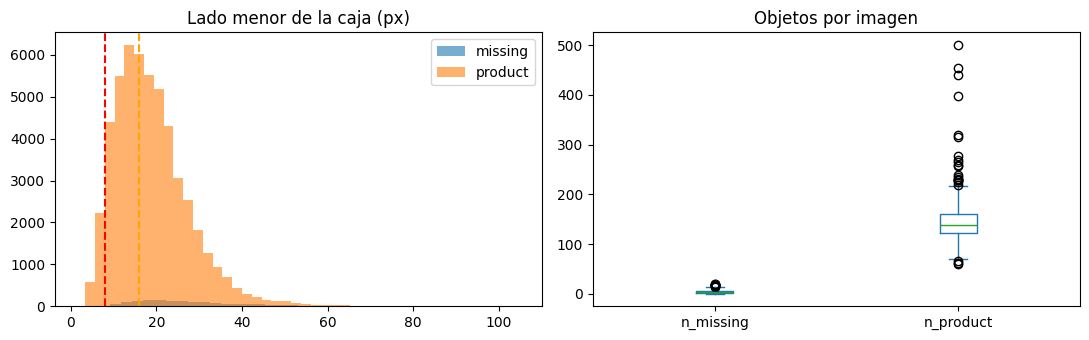

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image


def collect_stats(root, imgsz):
    """Una fila por caja con su tamaño en px tras el letterbox a `imgsz`, y una fila por imagen."""
    rows, per_image = [], []
    for ip, lp in list_pairs(root):
        W, H = Image.open(ip).size
        s = imgsz / max(W, H)
        boxes, classes = read_yolo_bboxes(lp)
        per_image.append({"image": ip.name, "W": W, "H": H,
                          **{f"n_{n}": classes.count(i) for i, n in enumerate(CLASS_NAMES)}})
        for (x, y, w, h), c in zip(boxes, classes):
            rows.append({"cls": CLASS_NAMES[c], "w_px": w * W * s, "h_px": h * H * s})
    return pd.DataFrame(rows), pd.DataFrame(per_image)


df_box, df_img = collect_stats(RAW_DIR, IMGSZ)
df_box["min_side"] = df_box[["w_px", "h_px"]].min(axis=1)

print(f"Imágenes: {len(df_img)} | resoluciones: {df_img.groupby(['W', 'H']).size().to_dict()}")
print("\nCajas por clase:")
print(df_box.groupby("cls").size().to_string())
print("\nObjetos por imagen:")
print(df_img[[f"n_{n}" for n in CLASS_NAMES]].describe().loc[["mean", "50%", "max"]].round(1).to_string())

print(f"\nLado menor de cada caja (px, a {IMGSZ} px):")
print(df_box.groupby("cls")["min_side"].describe(percentiles=[.05, .5, .95])
      [["min", "5%", "50%", "95%"]].round(1).to_string())
small = df_box.assign(lt8=df_box.min_side < 8, lt16=df_box.min_side < 16).groupby("cls")[["lt8", "lt16"]].mean() * 100
print("\n% de cajas con lado menor < 8 px / < 16 px:")
print(small.round(1).to_string())

p5_prod = df_box[df_box.cls == CLASS_NAMES[PRODUCT_ID]].min_side.quantile(0.05)
if p5_prod < 8:
    print(f"\nAVISO: el 5 % de los productos mide < {p5_prod:.1f} px. Con imgsz={IMGSZ} varios quedan bajo el stride mínimo; "
          "si el recall de `product` es bajo, considera imgsz=800/960 o inferencia por tiles (SAHI).")
else:
    print("\nOK: el tamaño de los productos es adecuado para stride 8 con este imgsz.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for name, g in df_box.groupby("cls"):
    ax[0].hist(g.min_side.clip(upper=150), bins=40, alpha=.6, label=name)
ax[0].axvline(8, c="r", ls="--"); ax[0].axvline(16, c="orange", ls="--")
ax[0].set_title("Lado menor de la caja (px)"); ax[0].legend()
df_img[[f"n_{n}" for n in CLASS_NAMES]].plot.box(ax=ax[1]); ax[1].set_title("Objetos por imagen")
plt.tight_layout(); plt.show()

## 4. Split 70 / 15 / 15 sin fugas de datos

Tu dataset trae ~200 imágenes y ningún `valid`/`test`. Con tan pocos datos, un corte aleatorio simple tiene dos problemas:

1. **Fugas:** si hay fotos casi idénticas (mismo local o góndola, ángulos cercanos), unas caen en train y otras en valid y el mAP se infla sin que el modelo generalice.
2. **Clase minoritaria:** `missing` tiene pocas cajas; un split desafortunado deja valid o test casi sin ejemplos.

**Qué hace la celda:**
- Calcula un *hash perceptual* (phash) por imagen y agrupa las casi-duplicadas. Cada grupo completo va a un único split.
- Si algún grupo supera `MAX_GROUP_FRAC` del dataset (las góndolas se parecen mucho entre sí), baja el umbral automáticamente.
- Prueba `N_SPLIT_TRIES` particiones aleatorias y elige la que más se acerca a 70/15/15 **tanto en imágenes como en cajas `missing`**.
- Guarda `split_manifest.csv` con qué imagen quedó en qué split (útil como evidencia en el informe).

**Regla de uso:** `valid` sirve para elegir `best.pt` y ajustar; `test` **no se toca** hasta la evaluación final.

In [ ]:
import imagehash


def compute_groups(hashes, thr):
    """Agrupa (union-find) imágenes cuya distancia phash es <= thr."""
    n = len(hashes)
    parent = list(range(n))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    for i in range(n):
        for j in range(i + 1, n):
            if hashes[i] - hashes[j] <= thr:
                ri, rj = find(i), find(j)
                if ri != rj:
                    parent[ri] = rj
    groups = {}
    for i in range(n):
        groups.setdefault(find(i), []).append(i)
    return list(groups.values())


def group_near_duplicates(paths, thr=HASH_THR, max_frac=MAX_GROUP_FRAC):
    """Baja el umbral hasta que el grupo más grande sea <= max_frac del dataset."""
    hashes = [imagehash.phash(Image.open(p)) for p in paths]
    n = len(paths)
    for t in range(thr, -1, -1):
        groups = compute_groups(hashes, t)
        if max(len(g) for g in groups) <= max_frac * n:
            break
    print(f"Umbral phash usado: {t} | grupos: {len(groups)} | tamaño del mayor: {max(len(g) for g in groups)}")
    return groups


def assign_groups(groups, n_total, ratios, seed):
    """Reparte grupos completos en test, valid y train hasta cumplir las cuotas de imágenes."""
    rng = random.Random(seed)
    order = groups[:]
    rng.shuffle(order)
    quota = {"test": ratios[2] * n_total, "valid": ratios[1] * n_total}
    assign = {"train": [], "valid": [], "test": []}
    for g in order:
        if len(assign["test"]) < quota["test"]:
            assign["test"] += g
        elif len(assign["valid"]) < quota["valid"]:
            assign["valid"] += g
        else:
            assign["train"] += g
    return assign


def split_score(assign, miss_counts, n_total, ratios):
    """Menor es mejor: desvío de proporciones de imágenes y de cajas `missing`, con penalización si faltan ejemplos."""
    total_miss = max(sum(miss_counts), 1)
    score = 0.0
    for sp, r in zip(("train", "valid", "test"), ratios):
        n_img = len(assign[sp])
        n_miss = sum(miss_counts[i] for i in assign[sp])
        score += abs(n_img / n_total - r) + abs(n_miss / total_miss - r)
        if sp != "train" and n_miss < MIN_MISSING_PER_SPLIT:
            score += 10.0
    return score


def split_summary(root, splits=("train", "valid", "test")):
    rows = []
    for sp in splits:
        pairs = list_pairs(root, splits=(sp,))
        row = {"split": sp, "imágenes": len(pairs)}
        for cid, name in enumerate(CLASS_NAMES):
            row[f"cajas {name}"] = sum(count_class(lp, cid) for _, lp in pairs)
        rows.append(row)
    return pd.DataFrame(rows).set_index("split")


def resplit(raw_dir, out_dir, ratios=SPLIT_RATIOS, seed=SEED):
    pairs = list_pairs(raw_dir)
    n = len(pairs)
    groups = group_near_duplicates([p[0] for p in pairs])
    miss = [count_class(lp, MISSING_ID) for _, lp in pairs]

    best, best_score = None, float("inf")
    for k in range(N_SPLIT_TRIES):
        a = assign_groups(groups, n, ratios, seed + k)
        s = split_score(a, miss, n, ratios)
        if s < best_score:
            best, best_score = a, s
    print(f"Mejor partición de {N_SPLIT_TRIES} intentos (score {best_score:.3f})")

    out = Path(out_dir)
    if out.exists():
        shutil.rmtree(out)
    rows = []
    for sp, idxs in best.items():
        (out / sp / "images").mkdir(parents=True)
        (out / sp / "labels").mkdir(parents=True)
        for i in idxs:
            ip, lp = pairs[i]
            shutil.copy2(ip, out / sp / "images" / ip.name)
            shutil.copy2(lp, out / sp / "labels" / lp.name)
            rows.append({"split": sp, "image": ip.name, "n_missing": miss[i]})
    pd.DataFrame(rows).to_csv(out / "split_manifest.csv", index=False)
    return split_summary(out)

In [ ]:
summary = resplit(RAW_DIR, SPLIT_DIR)
summary["% imágenes"] = (summary["imágenes"] / summary["imágenes"].sum() * 100).round(1)
miss_col = f"cajas {CLASS_NAMES[MISSING_ID]}"
summary["% missing"] = (summary[miss_col] / summary[miss_col].sum() * 100).round(1)
print(summary.to_string())

for sp in ("valid", "test"):
    if summary.loc[sp, miss_col] < MIN_MISSING_PER_SPLIT:
        print(f"AVISO: '{sp}' tiene pocas cajas missing; cambia SEED o sube N_SPLIT_TRIES.")

Umbral phash usado: 8 | grupos: 339 | tamaño del mayor: 2
Mejor partición de 300 intentos (score 0.011)
       imágenes  cajas missing  cajas product  % imágenes  % missing
split                                                               
train       243            994          35978        69.6       70.2
valid        53            211           7463        15.2       14.9
test         53            211           8421        15.2       14.9


## 5. Aumentación realista (solo train)

Las cámaras de seguridad cambian lo que ve el modelo en dos frentes, y cada uno tiene su pipeline:

**Geométrico** (modifica las cajas, se aplica con `bbox_params`):
- `Perspective` fuerte y `Affine`: cámaras en altura que miran la góndola en diagonal.
- `OpticalDistortion`: lentes gran angular (si tu versión de albumentations no la soporta con cajas, se omite sola).
- `HorizontalFlip`. **Se eliminó `VerticalFlip`**: ninguna góndola aparece al revés.
- `min_visibility=0.3` y `min_area=16`: se descartan cajas que la transformación dejó casi fuera de la imagen o diminutas.

**Degradación** (solo píxeles, las cajas no cambian):
- Baja resolución (`Downscale`), compresión JPEG, desenfoque de movimiento o foco, ruido de sensor.
- Cambios de brillo, contraste, gamma y sombras (iluminación de tienda).
- `ToGray`: cámaras en modo monocromo/infrarrojo.

**Reglas del pipeline de datos:**
- Solo se aumenta `train`. `valid` y `test` quedan limpios.
- Las imágenes que contienen `missing` generan más copias (`N_AUG_MISSING`) para compensar el desbalance, y la copia se descarta si la geometría eliminó todas sus cajas `missing`.
- Además se crean `valid_cam` y `test_cam`: copias **degradadas** (misma etiqueta) para medir cómo rinde el modelo en condiciones de cámara. Se usan solo para evaluar, nunca para elegir `best.pt`.
- Ultralytics aplica además su propia aumentación (mosaic, HSV, flip horizontal) durante el entrenamiento; por eso aquí no se repiten giros ni color agresivos.

In [ ]:
import albumentations as A
import cv2


def make_degradation_pipeline(p=0.95):
    """Simula una cámara de seguridad: baja resolución, compresión, ruido, desenfoque, iluminación."""
    return A.Compose([
        A.Downscale(scale_range=(0.30, 0.65), p=0.7),
        A.ImageCompression(quality_range=(20, 60), p=0.7),
        A.OneOf([
            A.MotionBlur(blur_limit=(3, 7), p=1.0),
            A.GaussianBlur(blur_limit=(3, 7), p=1.0),
            A.Defocus(radius=(3, 6), p=1.0),
        ], p=0.5),
        A.OneOf([
            A.ISONoise(color_shift=(0.01, 0.05), intensity=(0.1, 0.5), p=1.0),
            A.GaussNoise(std_range=(0.02, 0.08), p=1.0),
            A.MultiplicativeNoise(multiplier=(0.9, 1.1), p=1.0),
        ], p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.6),
        A.RandomGamma(gamma_limit=(70, 130), p=0.4),
        A.RandomToneCurve(scale=0.2, p=0.3),
        A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_limit=(1, 3), p=0.3),
        A.ToGray(p=0.08),   # cámaras monocromo / infrarrojo
    ], p=p)


def optical_distortion_supports_bboxes():
    """Comprueba (con p=1) si esta versión de albumentations transforma cajas con OpticalDistortion."""
    try:
        t = A.Compose([A.OpticalDistortion(distort_limit=(-0.3, 0.3), p=1.0)],
                      bbox_params=A.BboxParams(format="yolo", label_fields=["class_labels"]))
        t(image=np.zeros((480, 640, 3), np.uint8), bboxes=[[0.5, 0.5, 0.2, 0.2]], class_labels=[0])
        return True
    except Exception as e:
        print("OpticalDistortion omitida (no compatible con bboxes en esta versión):", type(e).__name__)
        return False


def build_geometric_pipeline(p=0.85):
    """Cambios de ángulo de cámara. NO incluye VerticalFlip."""
    transforms = [
        A.Perspective(scale=(0.05, 0.15), keep_size=True, p=0.7),
        A.Affine(rotate=(-10, 10), shear=(-8, 8), scale=(0.8, 1.15), p=0.6),
    ]
    if optical_distortion_supports_bboxes():
        transforms.append(A.OpticalDistortion(distort_limit=(-0.3, 0.3), p=0.3))
    transforms.append(A.HorizontalFlip(p=0.5))
    return A.Compose(
        transforms,
        bbox_params=A.BboxParams(format="yolo", label_fields=["class_labels"],
                                 clip=True, min_visibility=0.3, min_area=16),
        p=p,
    )


def seeded(pipeline, seed):
    """Fija la semilla del pipeline (albumentations >= 2.0); en versiones antiguas no hace nada."""
    if hasattr(pipeline, "set_random_seed"):
        pipeline.set_random_seed(seed)
    return pipeline


def draw_boxes(img_bgr, boxes, classes):
    """Dibuja cajas YOLO normalizadas: rojo = missing, verde = product."""
    out = img_bgr.copy()
    H, W = out.shape[:2]
    for (x, y, w, h), c in zip(boxes, classes):
        p1 = (int((x - w / 2) * W), int((y - h / 2) * H))
        p2 = (int((x + w / 2) * W), int((y + h / 2) * H))
        cv2.rectangle(out, p1, p2, (0, 0, 255) if c == MISSING_ID else (0, 200, 0), 2 if c == MISSING_ID else 1)
    return out

In [ ]:
def augment_train(src_split_dir, out_split_dir, geometric, degrade):
    """Copia cada imagen original de train y genera copias aumentadas (geometría -> degradación)."""
    img_dir, lbl_dir = Path(src_split_dir) / "images", Path(src_split_dir) / "labels"
    out_img, out_lbl = Path(out_split_dir) / "images", Path(out_split_dir) / "labels"
    out_img.mkdir(parents=True, exist_ok=True)
    out_lbl.mkdir(parents=True, exist_ok=True)

    n_orig = n_aug = 0
    for ip in sorted(img_dir.iterdir()):
        lp = lbl_dir / f"{ip.stem}.txt"
        img = cv2.imread(str(ip))
        if img is None or not lp.exists():
            continue
        boxes, classes = read_yolo_bboxes(lp)

        cv2.imwrite(str(out_img / ip.name), img)               # original sin modificar
        write_yolo_bboxes(out_lbl / lp.name, boxes, classes)
        n_orig += 1

        n_copies = N_AUG_MISSING if MISSING_ID in classes else N_AUG_DEFAULT
        for i in range(n_copies):
            for _ in range(3):                                  # hasta 3 intentos por copia
                g = geometric(image=img, bboxes=boxes, class_labels=classes)
                ok = len(g["bboxes"]) > 0 or len(boxes) == 0
                if MISSING_ID in classes and MISSING_ID not in list(g["class_labels"]):
                    ok = False                                  # se perdió el espacio vacío: reintenta
                if ok:
                    break
            else:
                continue
            aug_img = degrade(image=g["image"])["image"]
            name = f"{ip.stem}_aug{i}"
            cv2.imwrite(str(out_img / f"{name}{ip.suffix}"), aug_img)
            write_yolo_bboxes(out_lbl / f"{name}.txt", g["bboxes"], list(g["class_labels"]))
            n_aug += 1
    print(f"train: {n_orig} originales + {n_aug} aumentadas = {n_orig + n_aug} imágenes")


def make_cam_split(src_split_dir, out_split_dir, seed):
    """Copia un split degradando solo los píxeles (las etiquetas no cambian) para simular cámara."""
    degrade = seeded(make_degradation_pipeline(p=1.0), seed)
    img_dir, lbl_dir = Path(src_split_dir) / "images", Path(src_split_dir) / "labels"
    out_img, out_lbl = Path(out_split_dir) / "images", Path(out_split_dir) / "labels"
    out_img.mkdir(parents=True, exist_ok=True)
    out_lbl.mkdir(parents=True, exist_ok=True)
    for ip in sorted(img_dir.iterdir()):
        img = cv2.imread(str(ip))
        if img is None:
            continue
        cv2.imwrite(str(out_img / ip.name), degrade(image=img)["image"])
        shutil.copy2(lbl_dir / f"{ip.stem}.txt", out_lbl / f"{ip.stem}.txt")
    print(f"{Path(out_split_dir).name}: {len(list(out_img.iterdir()))} imágenes degradadas")

In [ ]:
import glob, os, psutil
from PIL import Image

paths = glob.glob("/content/split_dataset/train/images/*.*")
sizes = [Image.open(p).size for p in paths]
print("imágenes:", len(paths))
print("resoluciones más grandes:", sorted(set(sizes), key=lambda s: s[0] * s[1])[-3:])
print("mayor imagen:", round(max(w * h * 3 / 1e6 for w, h in sizes)), "MB sin comprimir")
print("RAM:", round(psutil.Process(os.getpid()).memory_info().rss / 1e9, 2), "GB en uso de", round(psutil.virtual_memory().total / 1e9, 1))

imágenes: 243
resoluciones más grandes: [(960, 720), (720, 960), (960, 960)]
mayor imagen: 3 MB sin comprimir
RAM: 0.79 GB en uso de 13.6


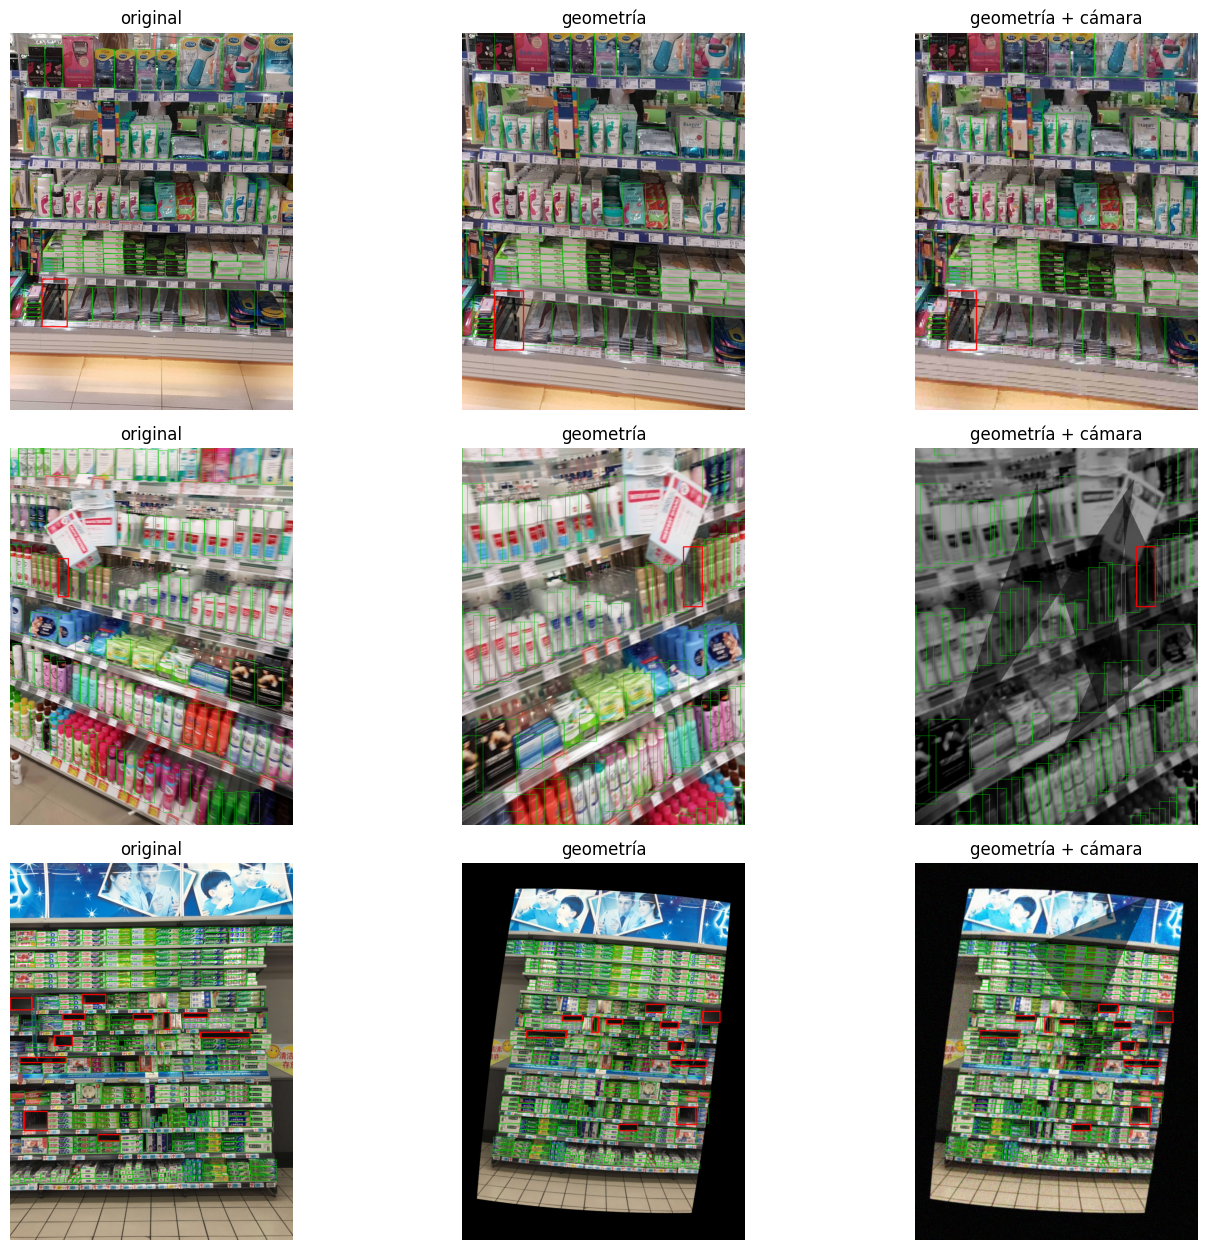

In [ ]:
# Revisión visual: original | geometría (ángulo de cámara) | geometría + degradación
# Rojo = missing, verde = product. Comprueba que las cajas siguen pegadas a los objetos.
def preview_augmentations(n=3):
    geometric = seeded(build_geometric_pipeline(), SEED)
    degrade = seeded(make_degradation_pipeline(), SEED)
    pairs = [(ip, lp) for ip, lp in list_pairs(SPLIT_DIR, splits=("train",)) if count_class(lp, MISSING_ID) > 0]
    random.Random(SEED).shuffle(pairs)

    fig, axes = plt.subplots(n, 3, figsize=(15, 4.2 * n))
    for row, (ip, lp) in enumerate(pairs[:n]):
        img = cv2.imread(str(ip))
        boxes, classes = read_yolo_bboxes(lp)
        g = geometric(image=img, bboxes=boxes, class_labels=classes)
        d = degrade(image=g["image"])["image"]
        panels = [("original", draw_boxes(img, boxes, classes)),
                  ("geometría", draw_boxes(g["image"], g["bboxes"], list(g["class_labels"]))),
                  ("geometría + cámara", draw_boxes(d, g["bboxes"], list(g["class_labels"])))]
        for col, (title, im) in enumerate(panels):
            axes[row, col].imshow(im[:, :, ::-1]); axes[row, col].set_title(title); axes[row, col].axis("off")
    plt.tight_layout(); plt.show()


preview_augmentations(3)

In [ ]:
def write_data_yaml(path, train, val, test):
    cfg = {"path": str(FINAL_DIR), "train": train, "val": val, "test": test,
           "nc": len(CLASS_NAMES), "names": CLASS_NAMES}
    with open(path, "w") as f:
        yaml.safe_dump(cfg, f, sort_keys=False, allow_unicode=True)


def build_final_dataset():
    if FINAL_DIR.exists():
        shutil.rmtree(FINAL_DIR)
    FINAL_DIR.mkdir(parents=True)

    geometric = seeded(build_geometric_pipeline(), SEED)
    degrade = seeded(make_degradation_pipeline(), SEED)
    augment_train(SPLIT_DIR / "train", FINAL_DIR / "train", geometric, degrade)

    for sp in ("valid", "test"):                       # limpios, sin aumentar
        shutil.copytree(SPLIT_DIR / sp, FINAL_DIR / sp)
    make_cam_split(SPLIT_DIR / "valid", FINAL_DIR / "valid_cam", seed=SEED + 1)
    make_cam_split(SPLIT_DIR / "test", FINAL_DIR / "test_cam", seed=SEED + 2)

    # data.yaml        -> entrenamiento y evaluación en imágenes limpias
    # data_cam.yaml    -> evaluación en imágenes degradadas (mismas etiquetas)
    write_data_yaml(FINAL_DIR / "data.yaml", "train/images", "valid/images", "test/images")
    write_data_yaml(FINAL_DIR / "data_cam.yaml", "train/images", "valid_cam/images", "test_cam/images")
    shutil.copy2(SPLIT_DIR / "split_manifest.csv", FINAL_DIR / "split_manifest.csv")


build_final_dataset()
print(split_summary(FINAL_DIR, splits=("train", "valid", "test", "valid_cam", "test_cam")).to_string())

train: 243 originales + 1352 aumentadas = 1595 imágenes
valid_cam: 53 imágenes degradadas
test_cam: 53 imágenes degradadas
           imágenes  cajas missing  cajas product
split                                            
train          1595           6005         201585
valid            53            211           7463
test             53            211           8421
valid_cam        53            211           7463
test_cam         53            211           8421


## 6. Entrenamiento: YOLOv8s

Se usa **YOLOv8s** (11 M de parámetros): la `n` se quedó corta (mAP50-95 estancado en 0,38) y la `m` memoriza con ~140 imágenes originales de train.

### Parámetros y por qué
| Parámetro | Valor | Motivo |
|---|---|---|
| `imgsz` | 640 | Grid 80×80 / 40×40 / 20×20. Múltiplo de 32. Se mantiene según lo definido |
| `epochs` / `patience` | 100 / 30 | 100 épocas fijas; el early stopping solo corta si no mejora en 30 |
| `batch` | 16 | Cabe en una T4 con `yolov8s` a 640 px |
| `max_det` | 500 | Hay ~150 productos por imagen; el valor por defecto (300) recorta detecciones en góndolas densas |
| `cls` | 1.0 | Peso de la pérdida de clasificación (defecto 0,5): ayuda a la clase minoritaria `missing` |
| `scale` | 0.3 | Defecto 0,5 (±50 % de zoom) encoge demasiado los productos pequeños; la escala ya se varía en la aumentación offline |
| `degrees`, `shear`, `perspective` | 0 | La geometría ya se aplicó offline con cajas validadas; no se duplica |
| `flipud` / `fliplr` | 0 / 0.5 | Sin volteo vertical; sí horizontal |
| `mosaic` / `close_mosaic` | 1.0 / 15 | Combina 4 imágenes (más objetos por imagen); se apaga en las últimas 15 épocas para afinar sobre imágenes reales |
| `hsv_h/s/v` | 0.015 / 0.5 / 0.4 | Variación de color moderada (cámaras con poca saturación) |
| `cos_lr` | True | Decaimiento suave del learning rate |
| `freeze` | 10 | Congela el backbone: menos sobreajuste con pocos datos |
| `seed` | 42 | Reproducibilidad |

In [ ]:
from ultralytics import YOLO

model = YOLO(MODEL_WEIGHTS)
results = model.train(
    data=str(FINAL_DIR / "data.yaml"),
    project=str(RUNS_DIR), name="yolov8s_v2",
    epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=PATIENCE, seed=SEED,
    max_det=500, rect=False,
    cls=1.0, freeze=FREEZE_LAYERS, cos_lr=True,
    # Aumentación en línea de Ultralytics (la geométrica fuerte ya se hizo offline)
    mosaic=1.0, close_mosaic=15,
    scale=0.3, translate=0.1, degrees=0.0, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.5,
    hsv_h=0.015, hsv_s=0.5, hsv_v=0.4,
    mixup=0.0,
)
SAVE_DIR = Path(model.trainer.save_dir)
BEST_PT = SAVE_DIR / "weights" / "best.pt"
print("Mejor modelo:", BEST_PT)

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=1.0, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/final_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=500, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_v2, nbs=64, nms=None, opset=None, optimize=False, o

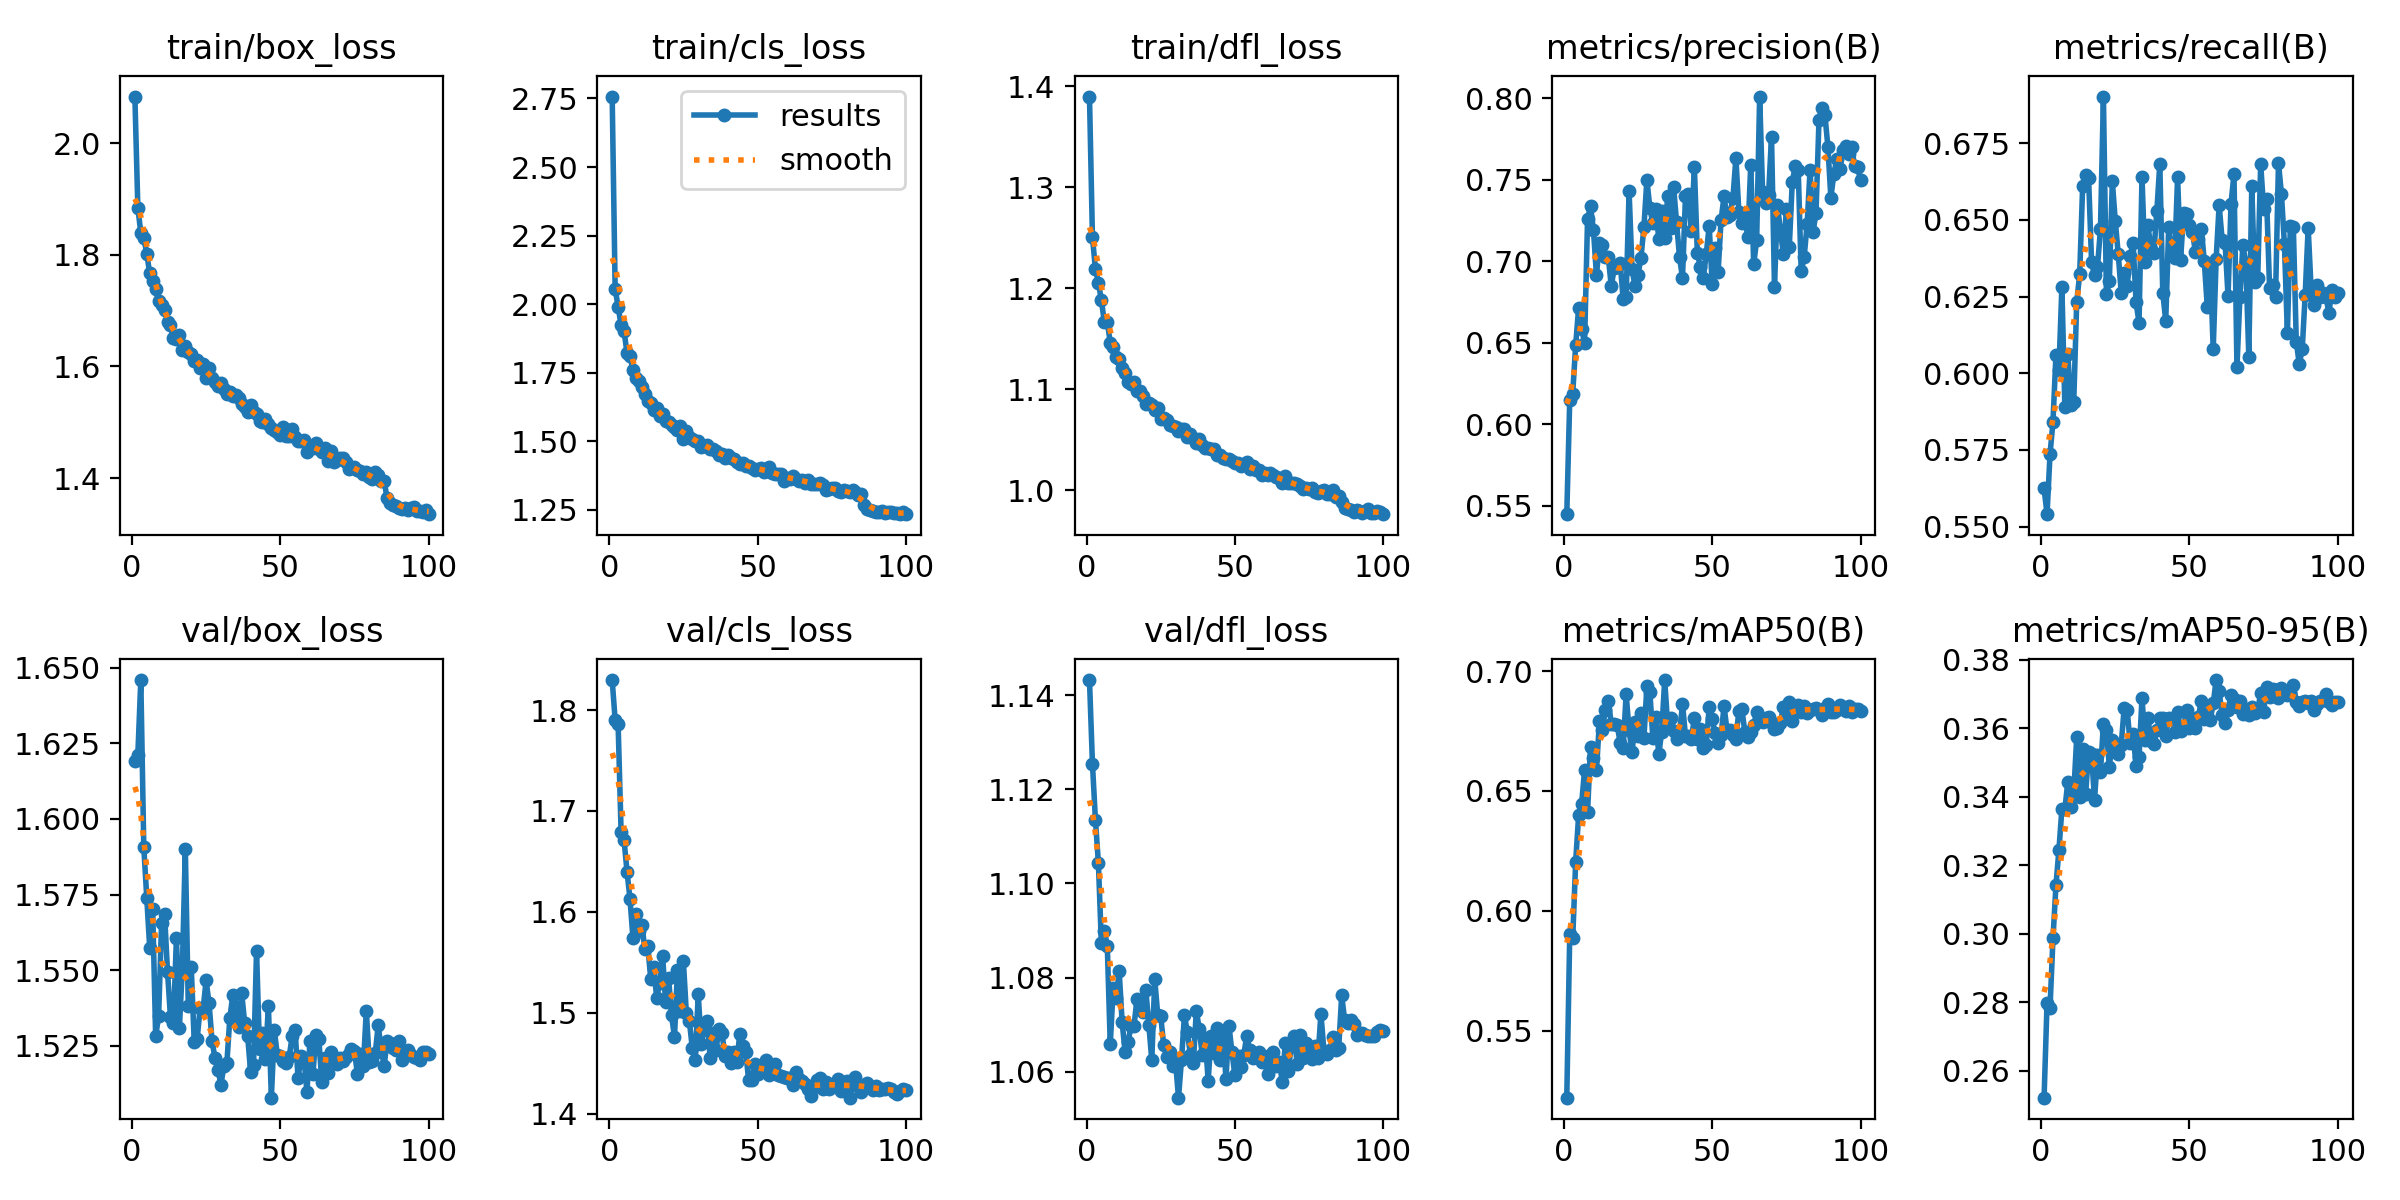

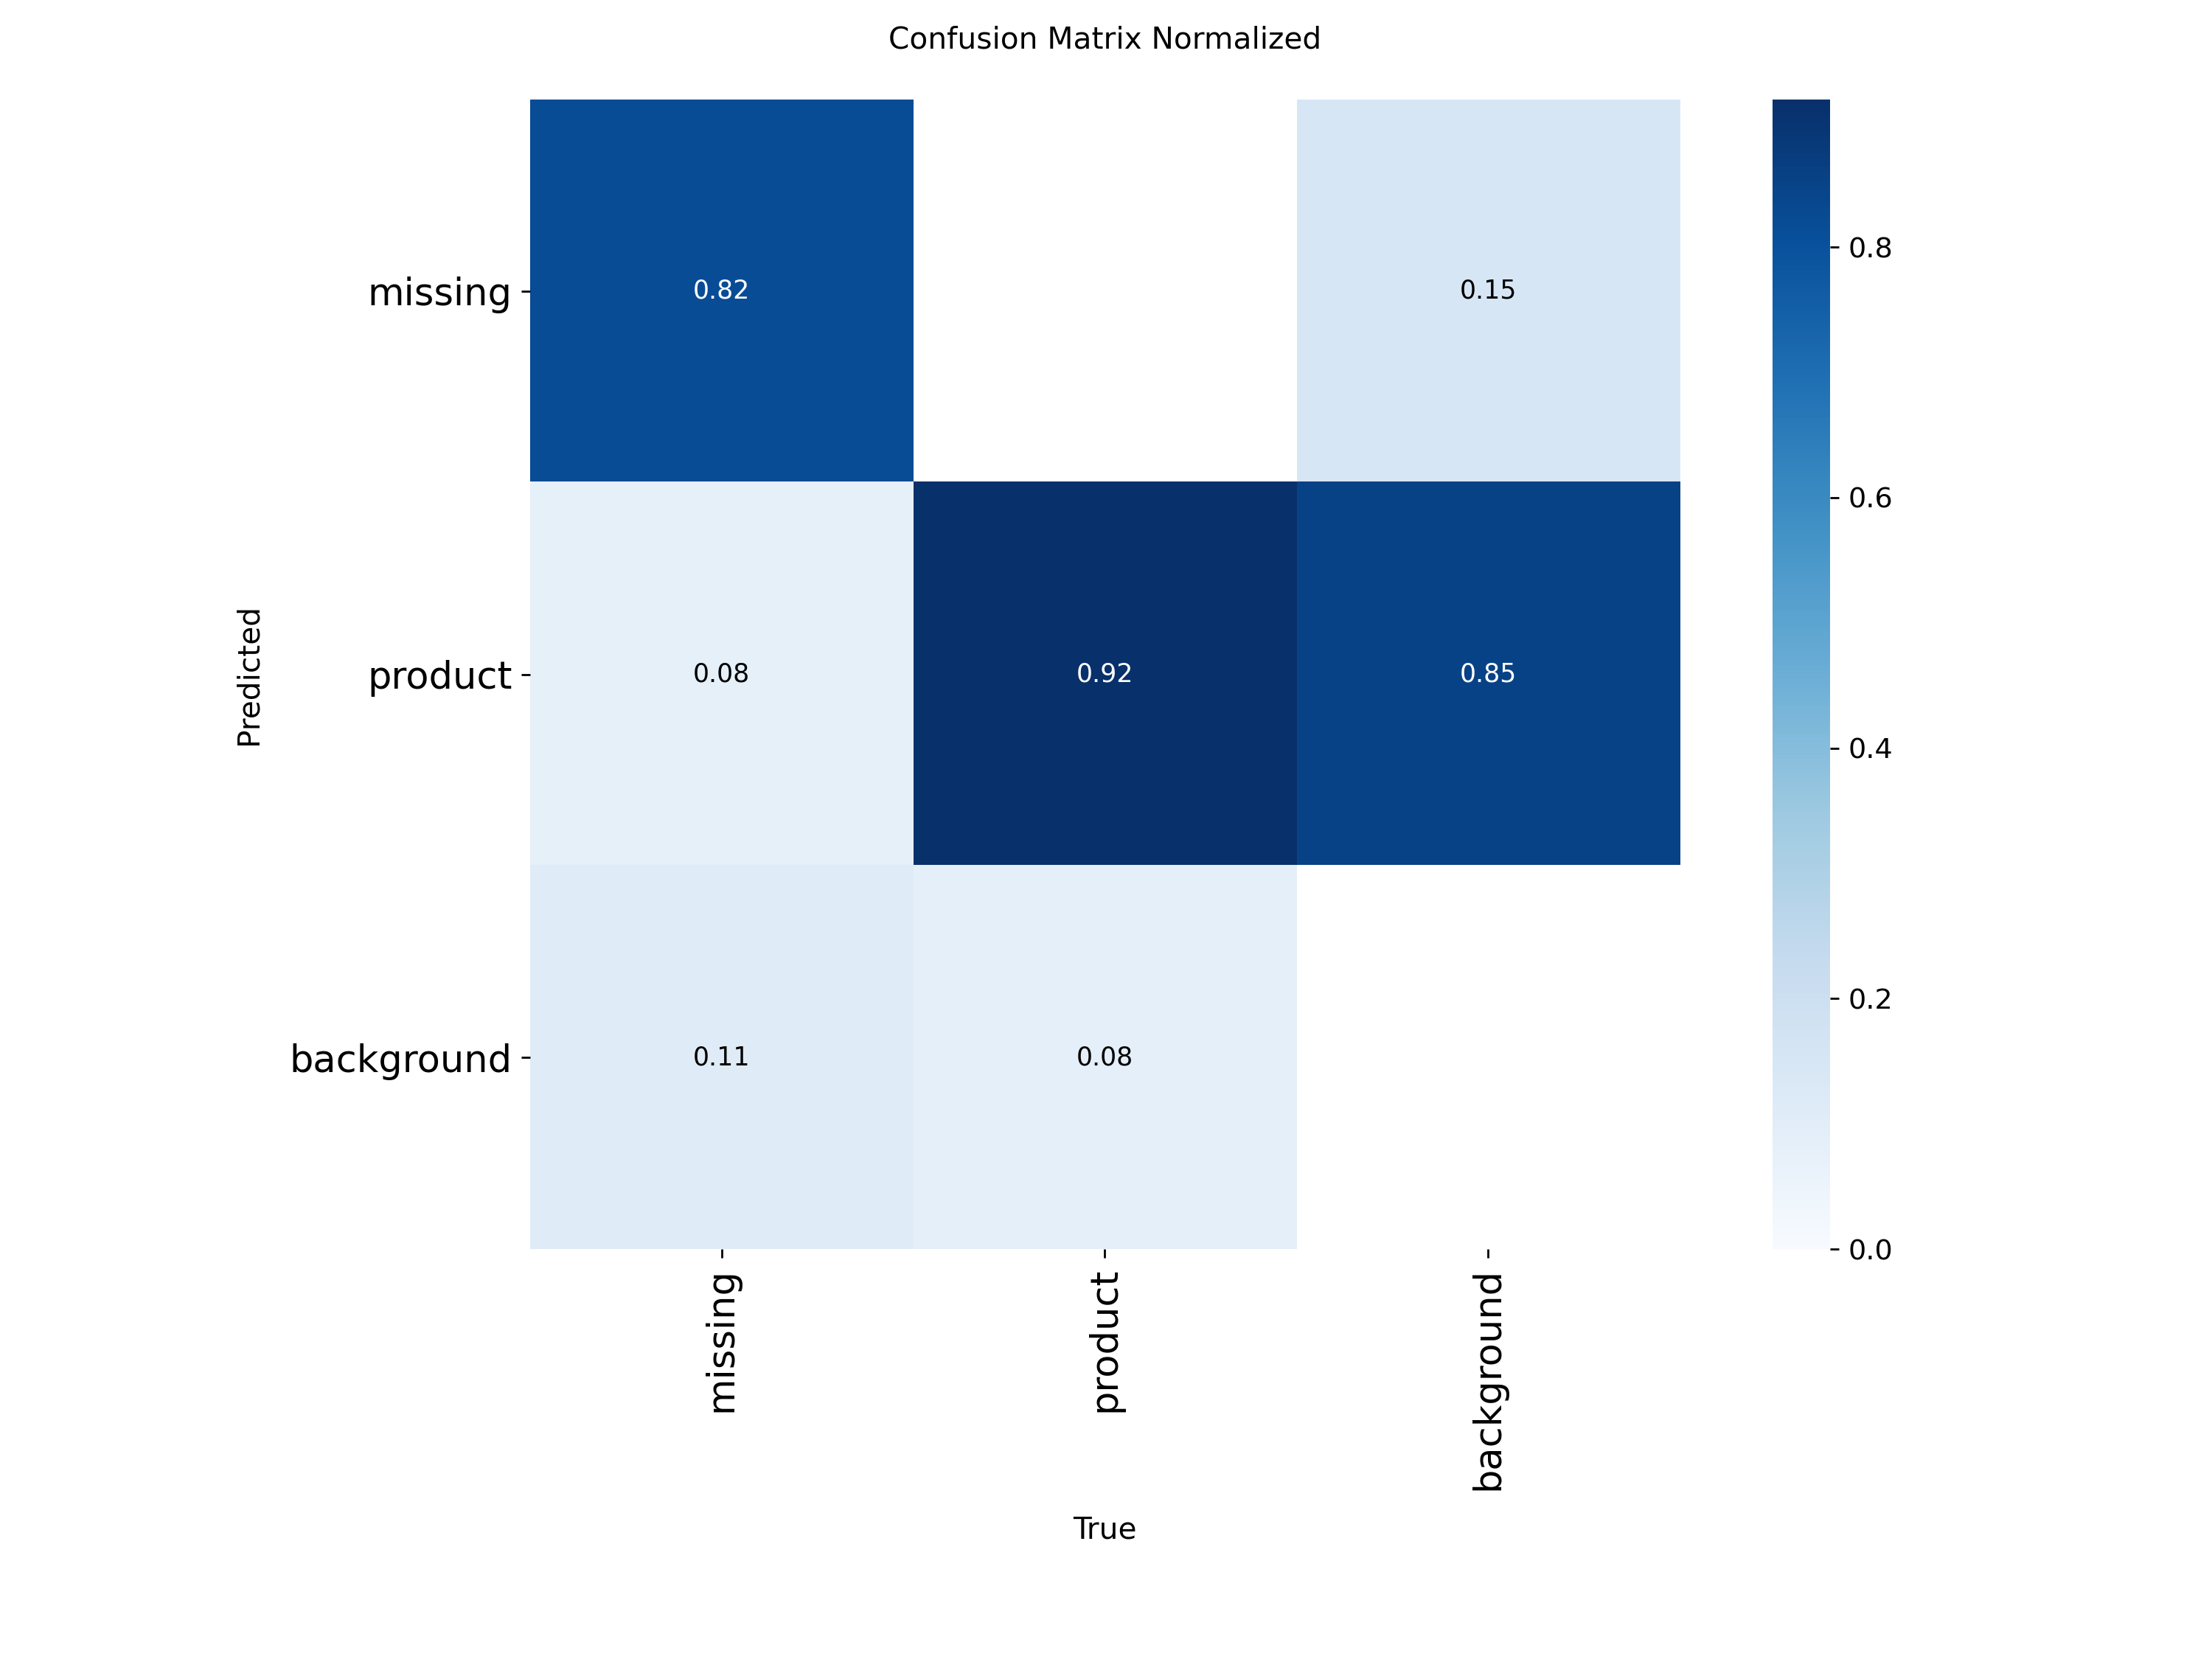

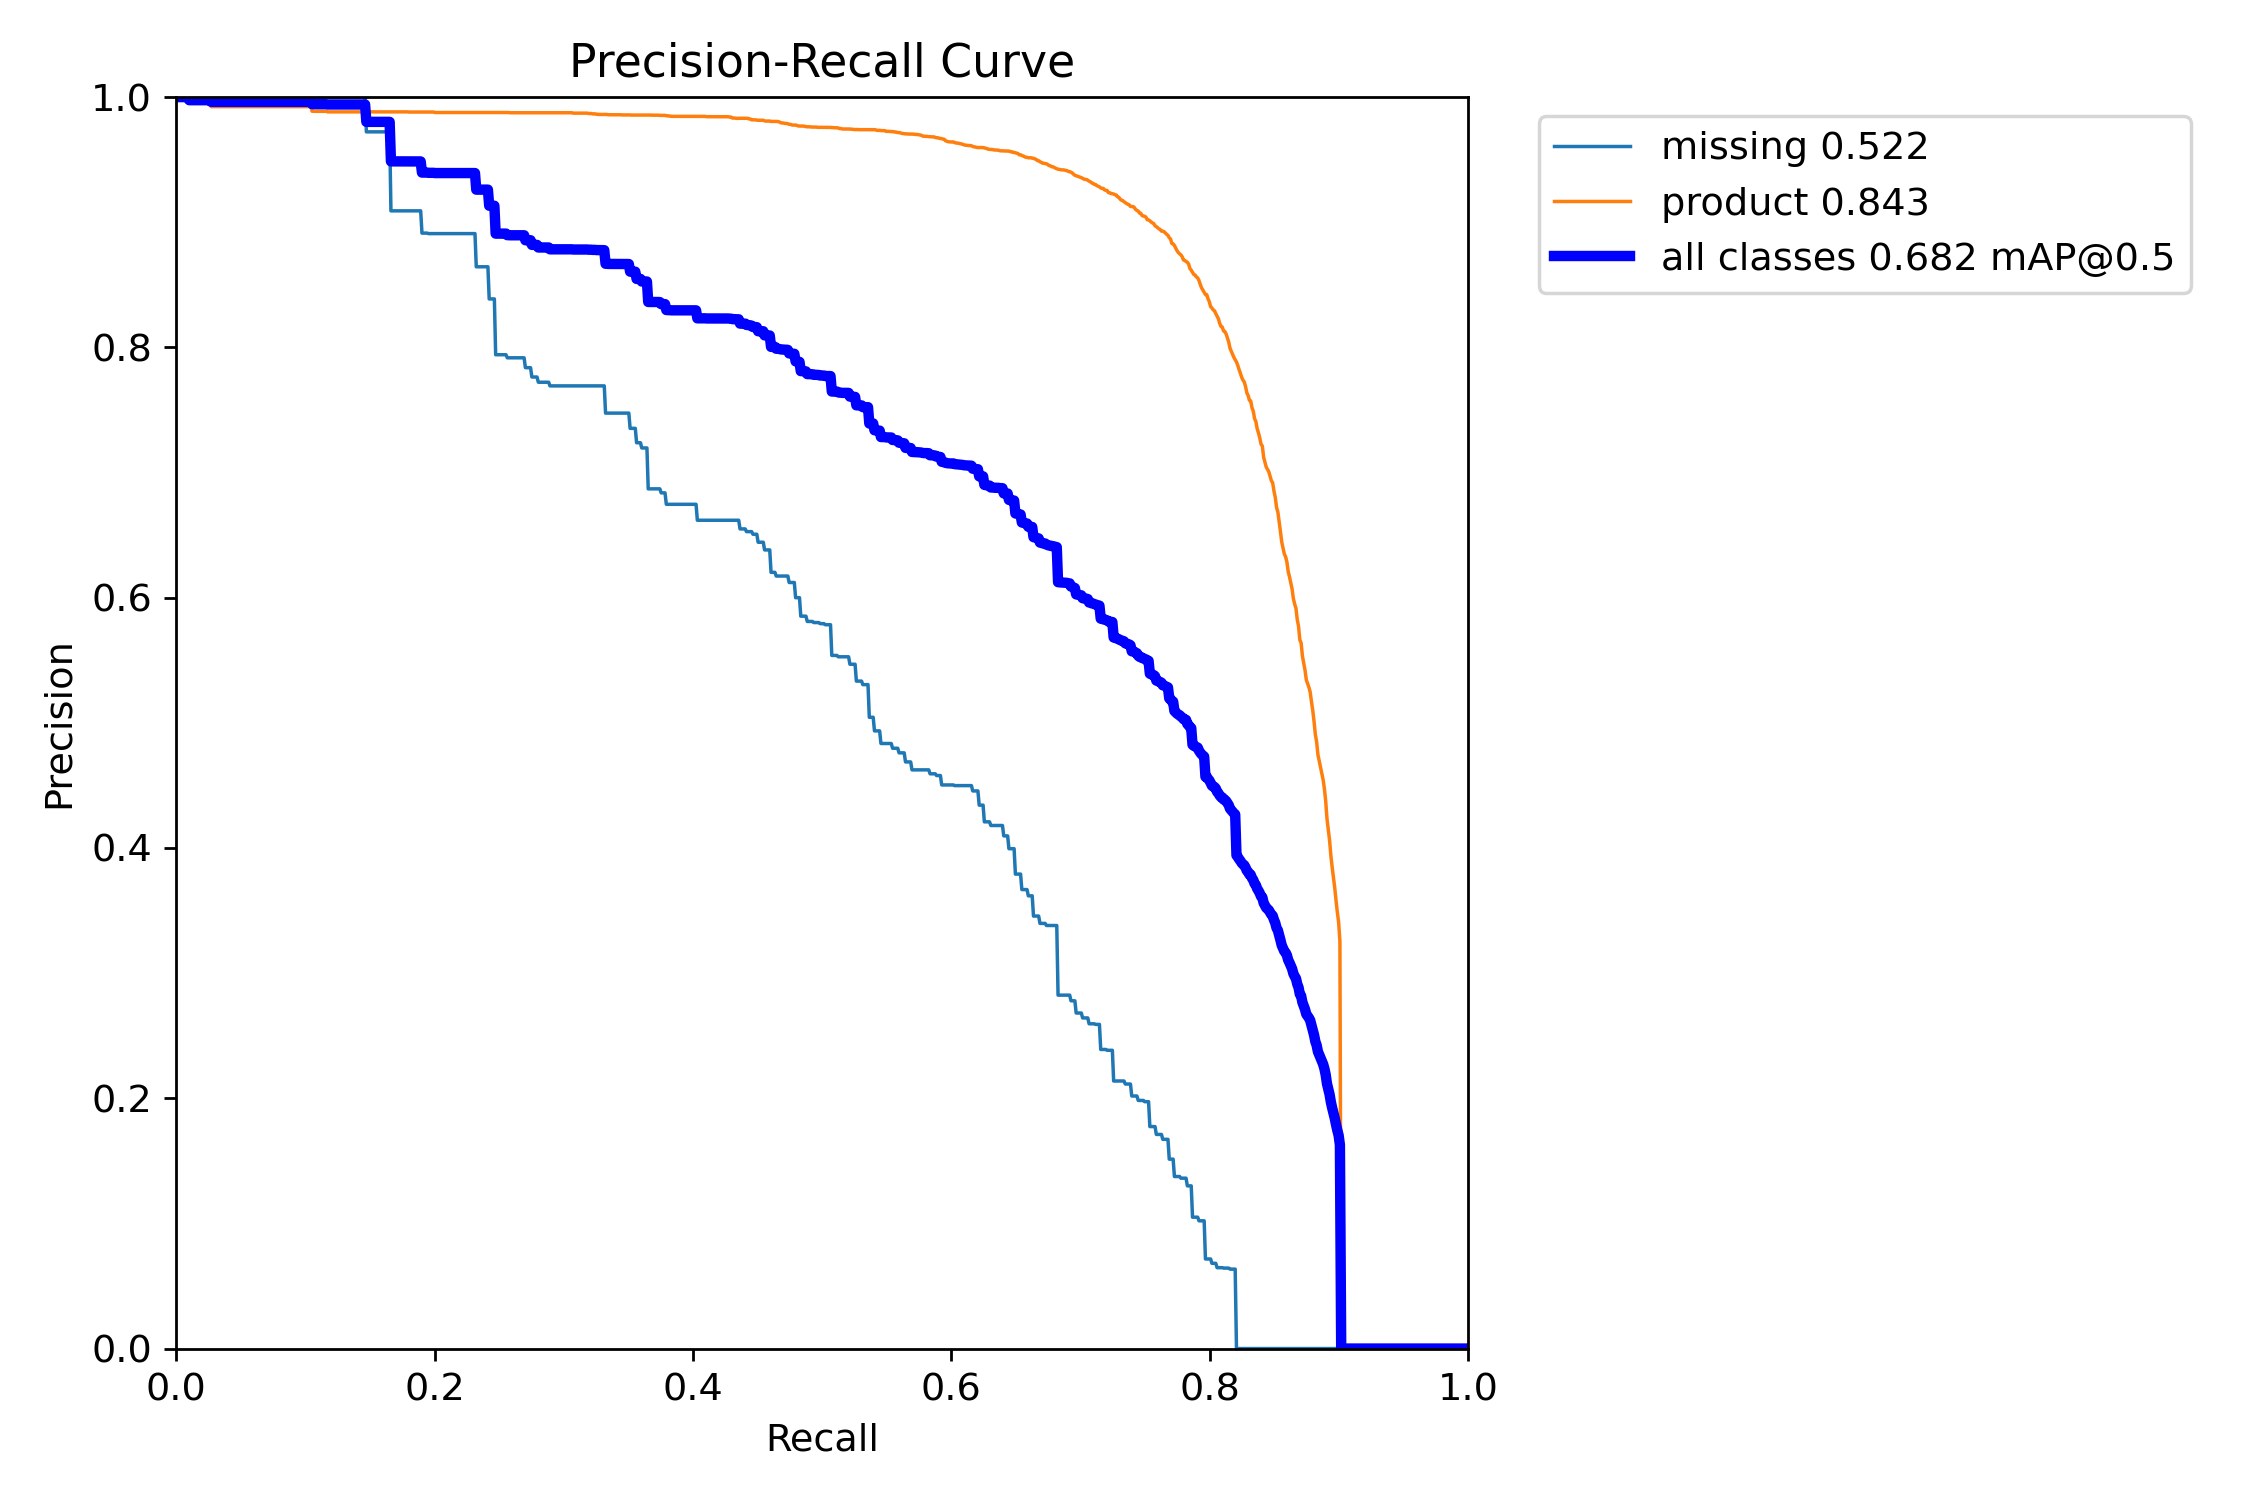

In [ ]:
from IPython.display import Image as IPyImage, display

for fname in ("results.png", "confusion_matrix_normalized.png", "BoxPR_curve.png"):
    f = SAVE_DIR / fname
    if f.exists():
        display(IPyImage(filename=str(f), width=900))

## 7. Evaluación

`best.pt` se eligió con `valid` limpio. Aquí se evalúa en cuatro conjuntos:

| Conjunto | Para qué |
|---|---|
| `valid` | Referencia (ya se usó para elegir `best.pt`, queda levemente optimista) |
| `valid_cam` | Cuánto cae el modelo con imágenes degradadas |
| `test` | **Número final del informe** (nunca visto) |
| `test_cam` | Rendimiento esperado con cámara de seguridad |

La **brecha limpio → cámara** (`mAP50-95` de `test` menos `test_cam`) es una métrica útil para la tesis: mide la sensibilidad a la calidad de imagen.

Con pocas imágenes, diferencias de ~0,02 en mAP son ruido. Mira sobre todo las métricas de `missing`.

In [ ]:
METRICS = {}


def evaluate(weights, data_yaml, split, tag):
    """Evalúa `weights` sobre un split del yaml y devuelve (fila de resultados, objeto de métricas)."""
    m = YOLO(str(weights))
    r = m.val(data=str(data_yaml), split=split, imgsz=IMGSZ, max_det=500,
              plots=False, verbose=False, project=str(RUNS_DIR / "eval"), name=tag, exist_ok=True)
    row = {"set": tag, "P": r.box.mp, "R": r.box.mr, "mAP50": r.box.map50, "mAP50-95": r.box.map}
    for i, c in enumerate(r.box.ap_class_index):
        n = CLASS_NAMES[int(c)]
        row[f"{n} P"], row[f"{n} R"] = r.box.p[i], r.box.r[i]
        row[f"{n} mAP50"], row[f"{n} mAP50-95"] = r.box.ap50[i], r.box.ap[i]
    METRICS[tag] = r
    return row


data_clean, data_cam = FINAL_DIR / "data.yaml", FINAL_DIR / "data_cam.yaml"
rows = [
    evaluate(BEST_PT, data_clean, "val", "valid"),
    evaluate(BEST_PT, data_cam, "val", "valid_cam"),
    evaluate(BEST_PT, data_clean, "test", "test"),
    evaluate(BEST_PT, data_cam, "test", "test_cam"),
]
RESULTS_TABLE = pd.DataFrame(rows).set_index("set").round(3)
print(RESULTS_TABLE.T.to_string())

for kind in ("valid", "test"):
    gap = RESULTS_TABLE.loc[kind, "mAP50-95"] - RESULTS_TABLE.loc[f"{kind}_cam", "mAP50-95"]
    print(f"\nBrecha limpio -> cámara en {kind}: {gap:+.3f} de mAP50-95")

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3817.4±887.2 MB/s, size: 326.5 KB)
val: Scanning /content/final_dataset/valid/labels.cache... 53 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 53/53 17.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.6it/s 1.6s
                   all         53       7674      0.738      0.642       0.68      0.375
Speed: 0.7ms preprocess, 9.3ms inference, 0.0ms loss, 1.7ms postprocess per image
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3019.8±585.0 MB/s, size: 292.1 KB)
val: Scanning /content/final_dataset/valid_cam/labels... 53 images,

In [ ]:
# Umbral de confianza recomendado: el que maximiza F1 en `valid` (no en test).
def smooth(y, k=21):
    return np.convolve(y, np.ones(k) / k, mode="same")

r = METRICS["valid"]
px, f1 = np.asarray(r.box.px), np.asarray(r.box.f1_curve)     # f1: (clases presentes, 1000)
f1_mean = smooth(f1.mean(0))
CONF = float(px[int(f1_mean.argmax())])
print(f"Confianza que maximiza el F1 medio: {CONF:.2f} (F1 = {f1_mean.max():.3f})")
for i, c in enumerate(r.box.ap_class_index):
    fc = smooth(f1[i])
    print(f"  {CLASS_NAMES[int(c)]:>8}: mejor conf {px[int(fc.argmax())]:.2f} | F1 {fc.max():.3f}")

Confianza que maximiza el F1 medio: 0.38 (F1 = 0.688)
   missing: mejor conf 0.38 | F1 0.551
   product: mejor conf 0.43 | F1 0.826


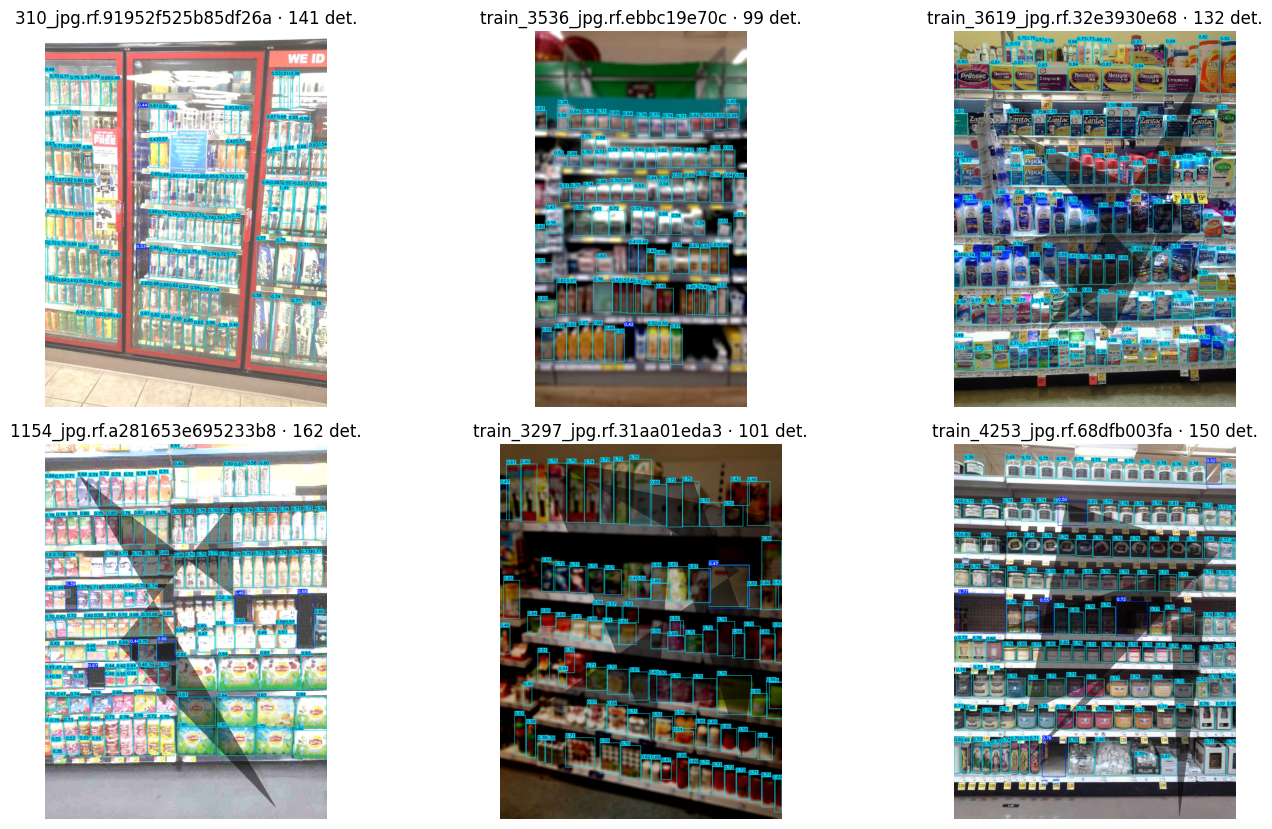

In [ ]:
def show_predictions(split="test_cam", n=6, conf=None):
    """Muestra predicciones del mejor modelo sobre imágenes de un split (rojo = missing, verde = product)."""
    conf = CONF if conf is None else conf
    m = YOLO(str(BEST_PT))
    paths = [ip for ip, _ in list_pairs(FINAL_DIR, splits=(split,))]
    random.Random(SEED).shuffle(paths)
    cols = 3
    fig, axes = plt.subplots((n + cols - 1) // cols, cols, figsize=(15, 4.2 * ((n + cols - 1) // cols)))
    for ax, p in zip(np.ravel(axes), paths[:n]):
        res = m.predict(str(p), conf=conf, imgsz=IMGSZ, max_det=500, verbose=False)[0]
        ax.imshow(res.plot(labels=False, line_width=1)[:, :, ::-1]); ax.set_title(f"{p.name[:28]} · {len(res.boxes)} det.")
        ax.axis("off")
    plt.tight_layout(); plt.show()


show_predictions("test_cam", n=6)

## 8. ¿Vale la pena usar SAM?

**Pregunta:** ¿SAM (Segment Anything) produce una máscara del espacio vacío mejor que la caja de YOLO, a un costo razonable?

Solo importa si el entregable necesita el **área exacta** del hueco. Un espacio vacío no tiene bordes claros (es el fondo de la góndola), así que SAM podría segmentar de más (el estante entero) o de menos. En vez de suponerlo, se mide.

**Cómo se usa:** SAM recibe como *prompt* la caja de un `missing` y devuelve una máscara. No se entrena nada.

### Prueba A — sin esfuerzo extra (siempre se ejecuta)
Con las cajas de `missing` de `test` y `test_cam` como prompts, se calcula para cada máscara:
- `cobertura` = fracción de la caja que la máscara llena. Muy baja ⇒ la máscara "colapsó".
- `fuga` = fracción de la máscara que cae **fuera** de la caja. Alta ⇒ SAM se desbordó (típico: segmenta el estante).
- tiempo por imagen.

### Prueba B — con verdad terreno (recomendada, ~20 imágenes)
Dibuja a mano **polígonos** de los espacios vacíos en ~20 imágenes de `test` (por ejemplo en Roboflow, herramienta polígono; **solo `missing`, un polígono por hueco**). Exporta como *YOLOv8 Segmentation* y deja los `.txt` en `GT_SEG_DIR`. Se compara el IoU de **la caja** contra el polígono real frente al IoU de **la máscara SAM** contra el mismo polígono. Los nombres se emparejan ignorando el sufijo `.rf.<hash>` que agrega Roboflow.

### Criterio de decisión (heurístico, ajústalo si quieres)
SAM vale la pena solo si:
1. mejora el IoU medio en al menos `SAM_MIN_GAIN` (0,05) frente a la caja, **y**
2. la fuga mediana es ≤ `SAM_MAX_LEAK` (0,25) y menos del `SAM_MAX_COLLAPSED` (30 %) de las máscaras colapsan, **y**
3. el tiempo por imagen es aceptable para tu caso (monitoreo cada pocos segundos, no tiempo real).

Si no se cumple, se descarta y se deja documentado como alternativa evaluada.

In [ ]:
SAM_N_IMAGES = 25                              # imágenes de test con 'missing' a analizar
GT_SEG_DIR = BASE / "gt_masks_missing"         # Prueba B: .txt YOLO-seg de ~20 imágenes de test (opcional)
SAM_MIN_GAIN = 0.05
SAM_MAX_LEAK = 0.25
SAM_MAX_COLLAPSED = 0.30
SAM_COLLAPSE_COV = 0.25                        # cobertura bajo este valor = máscara "colapsada"


def norm_key(stem):
    """Quita el sufijo '.rf.<hash>' de Roboflow para emparejar imágenes entre exportaciones."""
    return stem.split(".rf.")[0]


def gt_missing_boxes_xyxy(label_path, W, H):
    """Cajas `missing` en píxeles (x1, y1, x2, y2), usadas como prompts de SAM en la Prueba A."""
    boxes, classes = read_yolo_bboxes(label_path)
    return [[(x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H]
            for (x, y, w, h), c in zip(boxes, classes) if c == MISSING_ID]


def box_to_mask(box, W, H):
    m = np.zeros((H, W), dtype=bool)
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    m[max(y1, 0):min(y2, H), max(x1, 0):min(x2, W)] = True
    return m


def mask_iou(a, b):
    union = (a | b).sum()
    return float((a & b).sum() / union) if union else 0.0


def coverage_leak(mask, box_mask):
    """cobertura = parte de la caja que llena la máscara; fuga = parte de la máscara fuera de la caja."""
    cov = (mask & box_mask).sum() / max(box_mask.sum(), 1)
    leak = (mask & ~box_mask).sum() / max(mask.sum(), 1)
    return float(cov), float(leak)


def load_gt_index(gt_dir):
    """{clave normalizada: archivo .txt} de los polígonos dibujados a mano."""
    gt_dir = Path(gt_dir)
    return {norm_key(p.stem): p for p in gt_dir.glob("*.txt")} if gt_dir.exists() else {}


def load_gt_polygons(txt_path, W, H):
    """Lee polígonos YOLO-seg (cada línea: clase x1 y1 x2 y2 ...) y devuelve máscaras booleanas."""
    masks = []
    for line in open(txt_path):
        p = line.split()
        if len(p) < 7:
            continue
        pts = (np.array(p[1:], dtype=float).reshape(-1, 2) * [W, H]).astype(np.int32)
        m = np.zeros((H, W), np.uint8)
        cv2.fillPoly(m, [pts], 1)
        masks.append(m.astype(bool))
    return masks


def mask_to_box(mask):
    ys, xs = np.where(mask)
    return [int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1] if len(xs) else None

In [ ]:
import time
import torch
from ultralytics import SAM

sam = SAM("sam_b.pt")      # ~375 MB; se descarga solo la primera vez


def sam_masks(img_path, boxes_xyxy, W, H):
    """Segmenta con SAM usando cajas como prompt. Devuelve (máscaras booleanas HxW, segundos)."""
    t0 = time.time()
    res = sam(str(img_path), bboxes=[[float(v) for v in b] for b in boxes_xyxy], verbose=False)
    dt = time.time() - t0
    out = []
    for m in res[0].masks.data.cpu().numpy():
        if m.shape != (H, W):
            m = cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST)
        out.append(m.astype(bool))
    return out, dt

In [ ]:
GT_INDEX = load_gt_index(GT_SEG_DIR)
print(f"Polígonos de verdad terreno encontrados: {len(GT_INDEX)} imágenes" if GT_INDEX
      else "Sin verdad terreno en GT_SEG_DIR: solo se ejecuta la Prueba A.")


def run_sam_experiment(split, tag, max_images=SAM_N_IMAGES):
    """Prueba A (cobertura/fuga con cajas de `missing`) y Prueba B (IoU contra polígonos, si existen)."""
    pairs = [(ip, lp) for ip, lp in list_pairs(FINAL_DIR, splits=(split,)) if count_class(lp, MISSING_ID) > 0]
    random.Random(SEED).shuffle(pairs)
    rows_a, rows_b, examples, times = [], [], [], []

    for ip, lp in pairs[:max_images]:
        img = cv2.imread(str(ip))
        H, W = img.shape[:2]

        # ---- Prueba A: prompts = cajas `missing` etiquetadas ----
        boxes = gt_missing_boxes_xyxy(lp, W, H)
        if boxes:
            masks, dt = sam_masks(ip, boxes, W, H)
            times.append(dt)
            for b, m in zip(boxes, masks):
                cov, leak = coverage_leak(m, box_to_mask(b, W, H))
                rows_a.append({"set": tag, "image": ip.name, "coverage": cov, "leak": leak})
                if len(examples) < 6:
                    examples.append({"img": img, "box": b, "mask": m, "tag": tag})

        # ---- Prueba B: prompts = caja de cada polígono dibujado a mano ----
        gt_file = GT_INDEX.get(norm_key(ip.stem))
        if gt_file is not None:
            gts = load_gt_polygons(gt_file, W, H)
            gt_boxes = [mask_to_box(g) for g in gts]
            keep = [(g, b) for g, b in zip(gts, gt_boxes) if b is not None]
            if keep:
                masks, _ = sam_masks(ip, [b for _, b in keep], W, H)
                for (g, b), m in zip(keep, masks):
                    rows_b.append({"set": tag, "image": ip.name,
                                   "iou_box": mask_iou(box_to_mask(b, W, H), g), "iou_sam": mask_iou(m, g)})

    return pd.DataFrame(rows_a), pd.DataFrame(rows_b), examples, times


res_clean = run_sam_experiment("test", "test")
res_cam = run_sam_experiment("test_cam", "test_cam")
df_a = pd.concat([res_clean[0], res_cam[0]], ignore_index=True)
df_b = pd.concat([res_clean[1], res_cam[1]], ignore_index=True)
sam_times = res_clean[3] + res_cam[3]
sam_examples = res_clean[2][:3] + res_cam[2][:3]

if len(df_a):
    print("Prueba A — por conjunto (mediana):")
    print(df_a.groupby("set")[["coverage", "leak"]].median().round(3).to_string())
if len(df_b):
    print("\nPrueba B — IoU medio contra polígonos dibujados a mano:")
    print(df_b.groupby("set")[["iou_box", "iou_sam"]].mean().round(3).to_string())
print(f"\nTiempo de SAM: {np.mean(sam_times) * 1000:.0f} ms por imagen (GPU T4, todas las cajas de la imagen)" if sam_times else "")

Sin verdad terreno en GT_SEG_DIR: solo se ejecuta la Prueba A.
Prueba A — por conjunto (mediana):
          coverage   leak
set                      
test         0.719  0.097
test_cam     0.775  0.090

Tiempo de SAM: 503 ms por imagen (GPU T4, todas las cajas de la imagen)


Fuga mediana: 0.10 (máx. 0.25) | máscaras colapsadas: 2% (máx. 30%)
Costo: 503 ms por imagen con sam_b

VEREDICTO: NO CONCLUYENTE. La Prueba A solo detecta fallas evidentes; dibuja ~20 polígonos en GT_SEG_DIR para medir si SAM realmente mejora el área.


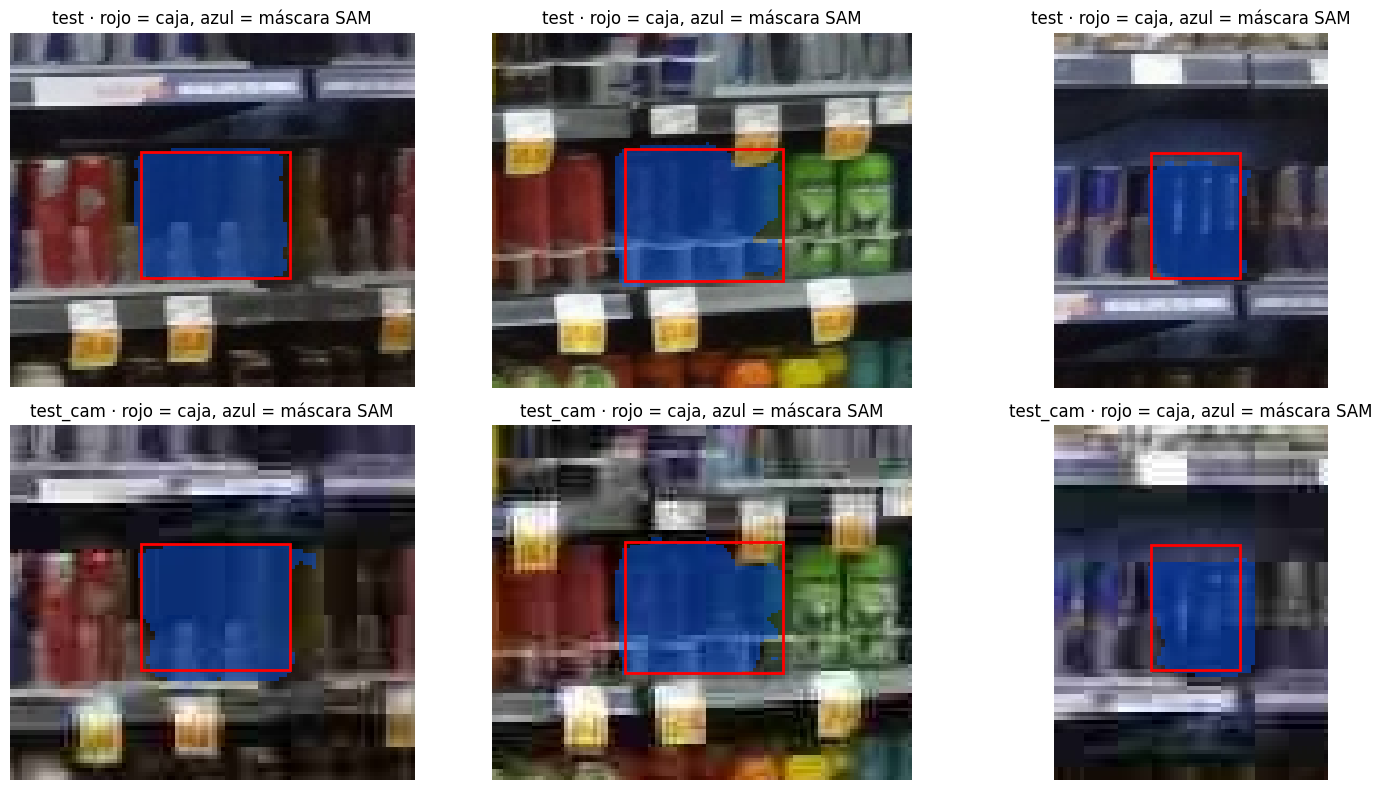

In [ ]:
def sam_verdict(df_a, df_b, times):
    """Aplica el criterio de decisión y devuelve un texto con el veredicto."""
    lines, checks = [], []
    if len(df_a):
        med_leak = df_a["leak"].median()
        frac_collapsed = float((df_a["coverage"] < SAM_COLLAPSE_COV).mean())
        reliable = med_leak <= SAM_MAX_LEAK and frac_collapsed <= SAM_MAX_COLLAPSED
        lines.append(f"Fuga mediana: {med_leak:.2f} (máx. {SAM_MAX_LEAK}) | máscaras colapsadas: {frac_collapsed:.0%} (máx. {SAM_MAX_COLLAPSED:.0%})")
        checks.append(reliable)
    if len(df_b):
        gain = df_b["iou_sam"].mean() - df_b["iou_box"].mean()
        lines.append(f"Mejora de IoU de SAM frente a la caja: {gain:+.3f} (mínimo {SAM_MIN_GAIN})")
        checks.append(gain >= SAM_MIN_GAIN)
    if times:
        lines.append(f"Costo: {np.mean(times) * 1000:.0f} ms por imagen con sam_b")

    print("\n".join(lines))
    if not len(df_b):
        print("\nVEREDICTO: NO CONCLUYENTE. La Prueba A solo detecta fallas evidentes; dibuja ~20 polígonos en GT_SEG_DIR "
              "para medir si SAM realmente mejora el área.")
    elif all(checks):
        print("\nVEREDICTO: VALE LA PENA como refinamiento en inferencia, solo sobre las cajas `missing` y si el área exacta es un requisito.")
    else:
        print("\nVEREDICTO: NO VALE LA PENA. Usa el área de la caja de YOLO y documenta SAM como alternativa evaluada.")


sam_verdict(df_a, df_b, sam_times)


def show_sam_examples(examples):
    """Caja (rojo) y máscara SAM (azul) sobre un recorte alrededor de cada hueco."""
    if not examples:
        return
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, ex in zip(np.ravel(axes), examples):
        img, (x1, y1, x2, y2), mask = ex["img"], ex["box"], ex["mask"]
        H, W = img.shape[:2]
        mx, my = int((x2 - x1) * 0.6) + 10, int((y2 - y1) * 0.6) + 10
        a, b, c, d = max(int(x1) - mx, 0), max(int(y1) - my, 0), min(int(x2) + mx, W), min(int(y2) + my, H)
        crop = img[b:d, a:c][:, :, ::-1].copy()
        overlay = crop.copy()
        overlay[mask[b:d, a:c]] = (0.55 * overlay[mask[b:d, a:c]] + 0.45 * np.array([0, 90, 255])).astype(np.uint8)
        ax.imshow(overlay)
        ax.add_patch(plt.Rectangle((x1 - a, y1 - b), x2 - x1, y2 - y1, fill=False, ec="red", lw=2))
        ax.set_title(f"{ex['tag']} · rojo = caja, azul = máscara SAM"); ax.axis("off")
    plt.tight_layout(); plt.show()


show_sam_examples(sam_examples)
del sam
torch.cuda.empty_cache()

## 9. Exportar y limitaciones

La última celda empaqueta `best.pt`, los `data.yaml`, el manifiesto del split y la tabla de resultados.

### Limitaciones que conviene declarar en el informe
- **Dataset pequeño** (~200 imágenes): las métricas tienen incertidumbre alta; reporta siempre el tamaño de `valid` y `test` y el número de cajas `missing` de cada uno.
- **Salto de dominio:** el dataset son fotos, no frames de cámaras reales. La aumentación simula resolución, ruido y ángulo, pero no reemplaza probar con video de cámaras de seguridad reales.
- **`test_cam` es sintético:** es la misma imagen degradada por el mismo pipeline de entrenamiento, así que es optimista frente a una cámara real.
- **Etiquetas de `missing`:** un hueco no tiene bordes definidos; un criterio de etiquetado distinto entre imágenes baja el mAP50-95.

In [ ]:
bundle = BASE / "entrega_modelo"
if bundle.exists():
    shutil.rmtree(bundle)
bundle.mkdir(parents=True)

shutil.copy2(BEST_PT, bundle / "best.pt")
for f in ("data.yaml", "data_cam.yaml", "split_manifest.csv"):
    shutil.copy2(FINAL_DIR / f, bundle / f)
RESULTS_TABLE.to_csv(bundle / "resultados_evaluacion.csv")
with open(bundle / "config.json", "w") as f:
    json.dump({"model": MODEL_WEIGHTS, "imgsz": IMGSZ, "epochs": EPOCHS, "seed": SEED,
               "conf_recomendada": CONF, "classes": CLASS_NAMES}, f, indent=2)

zip_path = shutil.make_archive(str(BASE / "entrega_modelo"), "zip", bundle)
print("Archivo listo:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Fuera de Colab: descarga el zip manualmente.")

Archivo listo: /content/entrega_modelo.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==== CASOS PARA EL INFORME: 10 mejores y 10 peores imágenes ====
# Compara lo que predice el modelo con las etiquetas reales, imagen por imagen.
SPLIT_CASOS = "test_cam"      # imágenes de test degradadas como cámara de seguridad
IOU_MATCH = 0.5               # una predicción cuenta como acierto si se superpone >= 50 % con la caja real
OUT_CASOS = BASE / f"casos_informe_{SPLIT_CASOS}"


def iou_xyxy(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def contar_aciertos(gt, pred, cls_id, thr=IOU_MATCH):
    """Devuelve (aciertos, falsos positivos, no detectados) para una clase."""
    g = [b for c, b in gt if c == cls_id]
    p = [b for c, b in pred if c == cls_id]
    usados, tp = set(), 0
    for gb in g:
        mejor, idx = 0.0, None
        for j, pb in enumerate(p):
            if j not in usados:
                v = iou_xyxy(gb, pb)
                if v > mejor:
                    mejor, idx = v, j
        if idx is not None and mejor >= thr:
            usados.add(idx)
            tp += 1
    return tp, len(p) - tp, len(g) - tp


def f1(tp, fp, fn):
    return None if tp + fp + fn == 0 else 2 * tp / (2 * tp + fp + fn)


def dibujar(img, cajas, titulo):
    out = img.copy()
    for c, (x1, y1, x2, y2) in cajas:
        color = (0, 0, 255) if c == MISSING_ID else (0, 200, 0)
        cv2.rectangle(out, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
    cv2.putText(out, titulo, (10, 35), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (255, 255, 255), 4)
    cv2.putText(out, titulo, (10, 35), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (0, 0, 0), 2)
    return out


modelo = YOLO(str(BEST_PT))
filas, cache = [], {}
for ip, lp in list_pairs(FINAL_DIR, splits=(SPLIT_CASOS,)):
    img = cv2.imread(str(ip))
    if img is None:
        continue
    H, W = img.shape[:2]
    boxes, classes = read_yolo_bboxes(lp)
    gt = [(c, [(x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H])
          for (x, y, w, h), c in zip(boxes, classes)]
    r = modelo.predict(str(ip), conf=CONF, imgsz=IMGSZ, max_det=500, verbose=False)[0]
    pred = [(int(c), list(map(float, b)))
            for b, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy())]

    fila = {"imagen": ip.name}
    puntajes = []
    for cid, nombre in ((PRODUCT_ID, "product"), (MISSING_ID, "missing")):
        tp, fp, fn = contar_aciertos(gt, pred, cid)
        fila.update({f"{nombre}_reales": tp + fn, f"{nombre}_aciertos": tp,
                     f"{nombre}_falsos_pos": fp, f"{nombre}_no_detectados": fn})
        valor = f1(tp, fp, fn)
        fila[f"{nombre}_F1"] = None if valor is None else round(valor, 3)
        if valor is not None:
            puntajes.append(valor)
    fila["puntaje"] = round(float(np.mean(puntajes)), 3) if puntajes else 0.0
    filas.append(fila)
    cache[ip.name] = (img, gt, pred)

df_casos = pd.DataFrame(filas).sort_values("puntaje", ascending=False).reset_index(drop=True)
n_top = min(10, len(df_casos) // 2)
grupos = {"mejores": df_casos.head(n_top), "peores": df_casos.tail(n_top).iloc[::-1]}

if OUT_CASOS.exists():
    shutil.rmtree(OUT_CASOS)
for grupo, df_g in grupos.items():
    (OUT_CASOS / grupo).mkdir(parents=True)
    for k, fila in enumerate(df_g.itertuples(), start=1):
        img, gt, pred = cache[fila.imagen]
        panel = np.hstack([dibujar(img, gt, "Real (etiquetas)"),
                           dibujar(img, pred, f"Modelo | puntaje {fila.puntaje:.2f}")])
        cv2.imwrite(str(OUT_CASOS / grupo / f"{k:02d}_{Path(fila.imagen).stem[:40]}.jpg"), panel)
df_casos.to_csv(OUT_CASOS / "casos_por_imagen.csv", index=False)

print(f"{len(df_casos)} imágenes evaluadas en '{SPLIT_CASOS}'. Verde = product, rojo = missing.")
for grupo, df_g in grupos.items():
    print(f"\n{grupo.upper()}:")
    print(df_g[["imagen", "puntaje", "product_F1", "missing_F1", "missing_reales",
                "missing_aciertos", "missing_falsos_pos", "missing_no_detectados"]].to_string(index=False))

zip_casos = shutil.make_archive(str(OUT_CASOS), "zip", OUT_CASOS)
print("\nArchivo listo:", zip_casos)

53 imágenes evaluadas en 'test_cam'. Verde = product, rojo = missing.

MEJORES:
                                                imagen  puntaje  product_F1  missing_F1  missing_reales  missing_aciertos  missing_falsos_pos  missing_no_detectados
        57_jpg.rf.6fd3d819f4b22dea69d9136f662fc9db.jpg    0.978       0.957       1.000               1                 1                   0                      0
       490_jpg.rf.3aa0b1e12e45ff2d5be9b95c282f9636.jpg    0.924       0.848       1.000               2                 2                   0                      0
train_4679_jpg.rf.0e1b7b9d60dcf528198431bb0c5562e4.jpg    0.885       0.913       0.857               8                 6                   0                      2
      1132_jpg.rf.352c65594ab6216718870f3fa15eeed3.jpg    0.858       0.858         NaN               0                 0                   0                      0
train_4861_jpg.rf.865cb1e56d9012c79ac59548a0c020ca.jpg    0.849       0.849         NaN        